<a href="https://colab.research.google.com/github/TaranAzrot-13/air-quality-forecast-milan/blob/main/air_quality_forecast_milan.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Next-day PM2.5 forecast: an honest evaluation

**Track:** AI + Climate, project 4.3.2 (Next-day air quality forecast).

**Team:** YONK by Gozzini Raffaele, Hnida Rayan and Singh Taranpreet

**Goal.** Forecast tomorrow's average fine-particle pollution (PM2.5) for one city, so schools and families know when to limit time outdoors.

### What this notebook contributes
1. **A fair baseline fight.** Tomorrow's PM2.5 is forecast and compared with the simple rule "tomorrow equals today", using a **time-ordered split** (no peeking at the future).
2. **An honesty check on weather.** Weather tomorrow is the strongest clue, but a real forecaster only has a *weather forecast*, not the weather that actually happened. We show the honest model and, separately, an optimistic upper bound, and label them clearly.
3. **Warnings designed for people.** A "limit outdoor time" warning for days above 35 µg/m³ (the US EPA 24-hour standard), with the balance between **missed warnings** and **false alarms** chosen with an explicit cost, using only the training period.
4. **Honest uncertainty.** A forecast range, and a check that the range really contains the truth as often as it claims.
5. **What drives pollution here:** season, wind and which inputs the model relies on.
6. **A replay demo** that shows past days next to what actually happened.

### How to run
`Runtime > Run all`. The city is set in the configuration cell (`CITY`, `COUNTRY`). Without an OpenAQ key the notebook uses Open-Meteo air-quality **model estimates** instead of station measurements (see the data section). It needs an internet connection and takes a few minutes.

### Contents
1. Setup · 2. Data · 3. Look at the data · 4. Features · 5. Split and baselines · 6. Models · 7. Stability across seasons · 8. Warnings · 9. Forecast ranges · 10. What drives pollution · 11. Key results · 12. Demo · 13. Limitations · 14. References

## 1. Setup and configuration

In [1]:
!pip install -q gradio

In [2]:
import os, time, math, warnings
import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt

from sklearn.linear_model import Ridge
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import TimeSeriesSplit
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_absolute_error, mean_squared_error

warnings.filterwarnings("ignore")

# ---------------- configuration: edit these ----------------
CITY = "Milan"            # <- the city we chose
COUNTRY = "IT"
LAT, LON = None, None
DATA_SOURCE = "auto"      # "auto", "openaq" (measurements) or "openmeteo" (model estimates)
OPENAQ_API_KEY = ""       # the OpenAQ key: store it in Colab Secrets as OPENAQ_API_KEY (never share a notebook with a key pasted in)

HISTORY_YEARS = 3         # how many years of history to download
TEST_DAYS = 120           # the most recent days kept aside for the final test
WARN_LEVEL = 35.0         # ug/m3: "limit outdoor time" (US EPA 24-hour standard)
CAUTION_LEVEL = 15.0      # ug/m3: "be careful" (WHO 24-hour guideline)
MISS_COST = 3.0           # a missed bad day counts this many times worse than a false alarm
SEED = 42
np.random.seed(SEED)

if not OPENAQ_API_KEY:
    try:
        from google.colab import userdata
        OPENAQ_API_KEY = userdata.get("OPENAQ_API_KEY") or ""
    except Exception:
        OPENAQ_API_KEY = os.environ.get("OPENAQ_API_KEY", "")
print("City:", CITY, "| OpenAQ key found:", bool(OPENAQ_API_KEY))

City: Milan | OpenAQ key found: True


In [3]:
from google.colab import userdata

## 2. Data
- **Air quality:** daily average PM2.5 from the nearest **OpenAQ** station with a good record (needs a free API key). If there is no key or no usable station, the notebook falls back to **Open-Meteo's air-quality API, which gives model estimates rather than measurements.** If that happens, we say so in our results and write-up, because a forecast of estimates is a weaker claim than a forecast of measurements.
- **Weather:** daily weather for the same place from **Open-Meteo's historical API** (temperature, humidity, rain, wind, pressure).
- Short gaps (up to 2 days) in PM2.5 are filled by interpolation, and the number of filled days is reported. Longer gaps are left empty and those days are not used.

In [4]:
END_DATE = (pd.Timestamp.today().normalize() - pd.Timedelta(days=7)).date()   # recent days may not be final yet
START_DATE = (pd.Timestamp(END_DATE) - pd.DateOffset(years=HISTORY_YEARS)).date()
OPENAQ = "https://api.openaq.org/v3"
WX_VARS = ["temperature_2m", "relative_humidity_2m", "precipitation", "wind_speed_10m",
           "wind_direction_10m", "surface_pressure"]

def get_json(url, params=None, headers=None, tries=3):
    last = None
    for i in range(tries):
        try:
            r = requests.get(url, params=params, headers=headers, timeout=60)
            if r.status_code == 200:
                return r.json()
            last = f"HTTP {r.status_code}: {r.text[:200]}"
            if r.status_code in (400, 401, 403, 422):
                break
        except requests.RequestException as e:
            last = str(e)
        time.sleep(2 * (i + 1))
    raise RuntimeError(f"Request failed for {url}: {last}")

def dist_km(lat1, lon1, lat2, lon2):
    p1, p2 = math.radians(lat1), math.radians(lat2)
    dphi, dl = p2 - p1, math.radians(lon2 - lon1)
    a = math.sin(dphi / 2) ** 2 + math.cos(p1) * math.cos(p2) * math.sin(dl / 2) ** 2
    return 6371 * 2 * math.asin(math.sqrt(a))

def year_chunks(start, end):
    s, e = pd.Timestamp(start), pd.Timestamp(end)
    while s <= e:
        c_end = min(s + pd.DateOffset(years=1) - pd.Timedelta(days=1), e)
        yield s.date().isoformat(), c_end.date().isoformat()
        s = c_end + pd.Timedelta(days=1)

def geocode(city, country=None):
    data = get_json("https://geocoding-api.open-meteo.com/v1/search",
                    {"name": city, "count": 10, "language": "en", "format": "json"})
    results = data.get("results") or []
    if country:
        results = [r for r in results if str(r.get("country_code", "")).upper() == country.upper()] or results
    if not results:
        raise RuntimeError(f"Could not find '{city}'. Set LAT and LON by hand in the configuration cell.")
    r = results[0]
    return r["latitude"], r["longitude"], r.get("name", city)

# ---------- Open-Meteo: air quality estimates ----------
def openmeteo_pm25_daily(lat, lon, start, end):
    frames = []
    for a, b in year_chunks(start, end):
        d = get_json("https://air-quality-api.open-meteo.com/v1/air-quality",
                     {"latitude": lat, "longitude": lon, "hourly": "pm2_5",
                      "start_date": a, "end_date": b, "timezone": "auto"})
        frames.append(pd.DataFrame({"time": pd.to_datetime(d["hourly"]["time"]), "pm25": d["hourly"]["pm2_5"]}))
    h = pd.concat(frames).dropna()
    h["date"] = h["time"].dt.normalize()
    g = h.groupby("date")["pm25"].agg(["mean", "count"])
    return g.loc[g["count"] >= 18, "mean"].rename("pm25")

# ---------- Open-Meteo: weather ----------
def openmeteo_weather_daily(lat, lon, start, end):
    frames = []
    for a, b in year_chunks(start, end):
        d = get_json("https://archive-api.open-meteo.com/v1/archive",
                     {"latitude": lat, "longitude": lon, "hourly": ",".join(WX_VARS),
                      "start_date": a, "end_date": b, "timezone": "auto"})
        h = pd.DataFrame(d["hourly"])
        h["time"] = pd.to_datetime(h["time"])
        frames.append(h)
    h = pd.concat(frames).drop_duplicates("time")
    rad = np.deg2rad(h["wind_direction_10m"])
    h["wind_u"] = -h["wind_speed_10m"] * np.sin(rad)     # wind vector, so averaging directions is safe
    h["wind_v"] = -h["wind_speed_10m"] * np.cos(rad)
    h["date"] = h["time"].dt.normalize()
    return h.groupby("date").agg(
        temp=("temperature_2m", "mean"), humidity=("relative_humidity_2m", "mean"),
        rain=("precipitation", "sum"), wind=("wind_speed_10m", "mean"),
        wind_u=("wind_u", "mean"), wind_v=("wind_v", "mean"), pressure=("surface_pressure", "mean"))

# ---------- OpenAQ: station measurements ----------
def openaq_find_sensors(lat, lon, radius=25000):
    headers = {"X-API-Key": OPENAQ_API_KEY}
    locs = []
    for coords in (f"{lat},{lon}", f"{lon},{lat}"):
        try:
            d = get_json(f"{OPENAQ}/locations",
                         {"coordinates": coords, "radius": radius, "parameters_id": 2, "limit": 100}, headers)
        except RuntimeError:
            continue
        near = [l for l in d.get("results", []) if l.get("coordinates")
                and dist_km(lat, lon, l["coordinates"]["latitude"], l["coordinates"]["longitude"]) <= radius / 1000 + 1]
        if near:
            locs = near
            break
    out = []
    for l in locs:
        km = dist_km(lat, lon, l["coordinates"]["latitude"], l["coordinates"]["longitude"])
        for s in l.get("sensors", []):
            if (s.get("parameter") or {}).get("id") == 2:   # parameter 2 = PM2.5
                out.append({"sensor_id": s["id"], "station": l.get("name"), "km": round(km, 1)})
    return sorted(out, key=lambda x: x["km"])

def openaq_pm25_daily(sensor_id, start, end):
    headers = {"X-API-Key": OPENAQ_API_KEY}
    rows, page = [], 1
    while True:
        d = get_json(f"{OPENAQ}/sensors/{sensor_id}/days",
                     {"datetime_from": f"{start}T00:00:00Z", "datetime_to": f"{end}T23:59:59Z",
                      "limit": 1000, "page": page}, headers)
        res = d.get("results", [])
        for r in res:
            try:
                date = str(r["period"]["datetimeFrom"]["local"])[:10]
            except (KeyError, TypeError):
                continue
            rows.append({"date": pd.Timestamp(date), "pm25": r.get("value"),
                         "coverage": (r.get("coverage") or {}).get("percentComplete")})
        if len(res) < 1000:
            break
        page += 1
        time.sleep(1)
    if not rows:
        return pd.Series(dtype=float, name="pm25")
    df = pd.DataFrame(rows)
    df = df[df["pm25"].notna() & (df["pm25"] >= 0) & (df["pm25"] < 1000)]
    df = df[df["coverage"].isna() | (df["coverage"] >= 75)]          # keep days that are mostly complete
    return df.drop_duplicates("date").set_index("date")["pm25"].sort_index().rename("pm25")

print("Data functions ready. Period:", START_DATE, "to", END_DATE)

Data functions ready. Period: 2023-11-09 to 2026-11-09


In [5]:
import json
from pathlib import Path

SNAPSHOT_FILE = "air_quality_snapshot.json"   # saved copy of the downloaded data
SNAPSHOT_URL = "https://raw.githubusercontent.com/TaranAzrot-13/air-quality-forecast-milan/main/air_quality_snapshot.json"
USE_SNAPSHOT = True      # use the saved copy when it matches the configured city

def read_snapshot():
    obj = None
    try:
        if USE_SNAPSHOT and Path(SNAPSHOT_FILE).exists():
            obj = json.load(open(SNAPSHOT_FILE))
        elif USE_SNAPSHOT and SNAPSHOT_URL:
            obj = get_json(SNAPSHOT_URL)
    except Exception as e:
        print("Could not read the saved data, downloading instead:", e)
        return None
    if obj is not None and (obj.get("config_city") != CITY or obj.get("config_country") != COUNTRY):
        print(f"The saved data is for {obj.get('config_city')}, not {CITY}. Downloading instead.")
        return None
    return obj

snap = read_snapshot()

if snap is not None:
    city_name, lat, lon = snap["city_name"], snap["lat"], snap["lon"]
    SOURCE_NOTE = snap["source_note"]
    n_missing_before, n_filled = snap["n_missing_before"], snap["n_filled"]
    daily = pd.DataFrame(snap["data"])
    daily["date"] = pd.to_datetime(daily["date"])
    daily = daily.set_index("date")
    print(f"Loaded the saved data snapshot for {city_name} (no downloads, no keys needed).")
    print("PM2.5 source:", SOURCE_NOTE)
else:
    if LAT is not None and LON is not None:
        lat, lon, city_name = LAT, LON, CITY
    else:
        lat, lon, city_name = geocode(CITY, COUNTRY)
    print(f"Location: {city_name} ({lat:.3f}, {lon:.3f})")

    pm, SOURCE_NOTE = None, None

    if DATA_SOURCE in ("auto", "openaq") and OPENAQ_API_KEY:
        try:
            sensors = openaq_find_sensors(lat, lon)
            print(f"OpenAQ: {len(sensors)} PM2.5 sensors within 25 km")
            best = None
            for s in sensors[:6]:
                series = openaq_pm25_daily(s["sensor_id"], START_DATE, END_DATE)
                print(f"  {s['station']} ({s['km']} km): {len(series)} usable days")
                if len(series) >= 300 and (best is None or len(series) > len(best[1])):
                    best = (s, series)
            if best is not None:
                pm = best[1]
                SOURCE_NOTE = f"OpenAQ station measurements: {best[0]['station']} ({best[0]['km']} km from the city centre)"
        except Exception as e:
            print("OpenAQ failed:", e)

    if pm is None:
        if DATA_SOURCE == "openaq":
            raise RuntimeError("No usable OpenAQ station found. Set DATA_SOURCE = 'auto' to use Open-Meteo estimates.")
        start_om = max(pd.Timestamp(START_DATE), pd.Timestamp("2022-08-01")).date()   # estimates start in Aug 2022
        pm = openmeteo_pm25_daily(lat, lon, start_om, END_DATE)
        SOURCE_NOTE = "Open-Meteo air-quality MODEL ESTIMATES (not station measurements)"

    print("PM2.5 source:", SOURCE_NOTE)

    wx = openmeteo_weather_daily(lat, lon, pm.index.min().date(), END_DATE)
    full_index = pd.date_range(pm.index.min(), min(pm.index.max(), wx.index.max()), freq="D")
    daily = pd.DataFrame({"pm25": pm}).reindex(full_index).join(wx)
    n_missing_before = int(daily["pm25"].isna().sum())
    daily["pm25"] = daily["pm25"].interpolate(limit=2, limit_area="inside")
    n_filled = n_missing_before - int(daily["pm25"].isna().sum())


    out = daily.rename_axis("date").reset_index()
    out["date"] = out["date"].dt.strftime("%Y-%m-%d")
    with open(SNAPSHOT_FILE, "w") as f:
        json.dump({"config_city": CITY, "config_country": COUNTRY, "city_name": city_name,
                   "lat": float(lat), "lon": float(lon), "source_note": SOURCE_NOTE,
                   "n_missing_before": n_missing_before, "n_filled": n_filled,
                   "data": {c: [None if pd.isna(v) else v for v in out[c].tolist()] for c in out.columns}}, f)
    print(f"Saved {SNAPSHOT_FILE}. Commit this file with the notebook so others can rerun it without any keys.")

print(f"Days: {len(daily)} ({daily.index.min().date()} to {daily.index.max().date()})")
print(f"PM2.5 missing: {n_missing_before} days; {n_filled} short gaps filled, {int(daily['pm25'].isna().sum())} left empty")
daily.head()

Loaded the saved data snapshot for Milan (no downloads, no keys needed).
PM2.5 source: OpenAQ station measurements: Porta Venezia (2.2 km from the city centre)
Days: 725 (2024-11-14 to 2026-11-08)
PM2.5 missing: 72 days; 17 short gaps filled, 55 left empty


,pm25,temp,humidity,rain,wind,wind_u,wind_v,pressure
date,,,,,,,,
2024-11-14,47.2,7.454167,80.166667,0.1,4.404167,-3.450613,-1.089410,1006.145833
2024-11-15,81.0,5.570833,90.166667,0.0,2.737500,-0.307518,-0.947962,1006.445833
2024-11-16,112.0,4.220833,95.416667,0.0,3.720833,2.343275,-0.911183,1005.554167
2024-11-17,79.4,5.404167,92.083333,0.0,3.004167,1.840228,-0.841958,997.854167
2024-11-18,103.0,6.820833,92.416667,0.0,2.383333,-1.065995,-1.708843,995.816667


## 3. Look at the data first

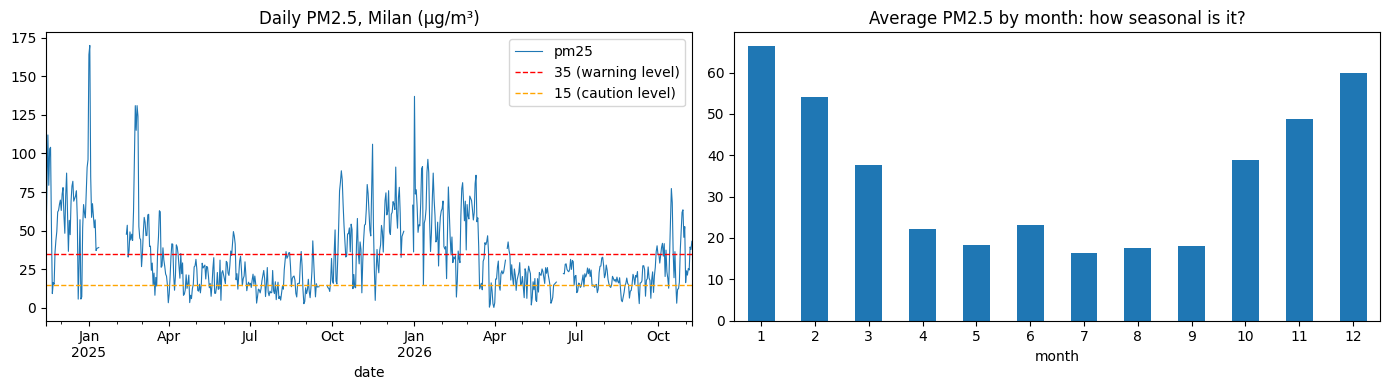

Days at or above 35 µg/m³: 251 of 670 (37.5%)
Days at or above 15 µg/m³: 522 of 670 (77.9%)


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
daily["pm25"].plot(ax=axes[0], lw=0.8)
axes[0].axhline(WARN_LEVEL, color="red", ls="--", lw=1, label=f"{WARN_LEVEL:.0f} (warning level)")
axes[0].axhline(CAUTION_LEVEL, color="orange", ls="--", lw=1, label=f"{CAUTION_LEVEL:.0f} (caution level)")
axes[0].set_title(f"Daily PM2.5, {city_name} (µg/m³)")
axes[0].legend()

monthly = daily["pm25"].groupby(daily.index.month).mean()
monthly.plot.bar(ax=axes[1], rot=0)
axes[1].set_title("Average PM2.5 by month: how seasonal is it?")
axes[1].set_xlabel("month")
plt.tight_layout()
plt.show()

valid = daily["pm25"].dropna()
print(f"Days at or above {WARN_LEVEL:.0f} µg/m³: {int((valid >= WARN_LEVEL).sum())} of {len(valid)} ({(valid >= WARN_LEVEL).mean():.1%})")
print(f"Days at or above {CAUTION_LEVEL:.0f} µg/m³: {int((valid >= CAUTION_LEVEL).sum())} of {len(valid)} ({(valid >= CAUTION_LEVEL).mean():.1%})")

## 4. Features
Everything a forecaster would know **today** is used to predict **tomorrow**:
- today's PM2.5, yesterday's, the 7-day average and the one-day change;
- today's weather and the time of year.

Tomorrow's weather is kept in a *separate* set. At forecast time a real forecaster only has a weather *forecast*, and here we only have what actually happened, so a model that uses it is optimistic. We report it as an **upper bound**, never as the headline result.

In [7]:
d = daily.copy()
d["pm_today"] = d["pm25"]
d["pm_lag1"] = d["pm25"].shift(1)
d["pm_lag2"] = d["pm25"].shift(2)
d["pm_mean7"] = d["pm25"].rolling(7, min_periods=5).mean()
d["pm_change"] = d["pm_today"] - d["pm_lag1"]
doy = d.index.dayofyear
d["season_sin"] = np.sin(2 * np.pi * doy / 365.25)
d["season_cos"] = np.cos(2 * np.pi * doy / 365.25)
d["tomorrow_weekend"] = ((d.index + pd.Timedelta(days=1)).dayofweek >= 5).astype(int)

WX = ["temp", "humidity", "rain", "wind", "wind_u", "wind_v", "pressure"]
for c in WX:
    d["wx_" + c] = d[c]                    # weather today
    d["fx_" + c] = d[c].shift(-1)          # weather tomorrow (only known after the fact)
d["target"] = d["pm25"].shift(-1)          # tomorrow's PM2.5

PM_FEATS = ["pm_today", "pm_lag1", "pm_lag2", "pm_mean7", "pm_change"]
CAL_FEATS = ["season_sin", "season_cos", "tomorrow_weekend"]
HONEST = PM_FEATS + ["wx_" + c for c in WX] + CAL_FEATS
ORACLE = HONEST + ["fx_" + c for c in WX]

model_df = d.dropna(subset=ORACLE + ["target"])
print("Usable days:", len(model_df), "| honest features:", len(HONEST), "| with tomorrow's weather:", len(ORACLE))

Usable days: 642 | honest features: 15 | with tomorrow's weather: 22


## 5. Split and baselines
The split follows time: the **most recent days** are the test set, and everything before them (minus a one-day gap, so no training label overlaps the test period) is training data. A random split would let the model learn from days next to the ones it is tested on and would flatter it.

Baselines: **persistence** ("tomorrow equals today", the required baseline) and the **3-day average**.

In [8]:
test_start = model_df.index[-TEST_DAYS]
train = model_df[model_df.index < test_start - pd.Timedelta(days=1)]
test = model_df[model_df.index >= test_start]
print(f"Training: {train.index.min().date()} to {train.index.max().date()} ({len(train)} days)")
print(f"Test:     {test.index.min().date()} to {test.index.max().date()} ({len(test)} days)")

def scores(y_true, y_pred):
    return {"MAE": mean_absolute_error(y_true, y_pred), "RMSE": mean_squared_error(y_true, y_pred) ** 0.5}

y_test = test["target"]
persist = test["pm_today"]
mean3 = test[["pm_today", "pm_lag1", "pm_lag2"]].mean(axis=1)

rows = [("Baseline: tomorrow = today", scores(y_test, persist)),
        ("Baseline: 3-day average", scores(y_test, mean3))]
pd.DataFrame({n: s for n, s in rows}).T.round(2)

Training: 2024-11-18 to 2026-07-09 (521 days)
Test:     2026-07-11 to 2026-11-07 (120 days)


,MAE,RMSE
Baseline: tomorrow = today,6.70,9.39
Baseline: 3-day average,7.97,11.57


## 6. Models
Two models, trained on the training period only:
- **Ridge regression:** a simple, transparent linear model.
- **Gradient boosting** (optimising absolute error, so it targets the same metric we report).

Each is trained on the **honest** feature set. Gradient boosting is also trained with tomorrow's *actual* weather, as the **optimistic upper bound**.

In [9]:
def make_ridge():
    return make_pipeline(StandardScaler(), Ridge(alpha=10.0))

def make_hgb():
    return HistGradientBoostingRegressor(loss="absolute_error", max_iter=300, learning_rate=0.05,
                                         max_leaf_nodes=15, min_samples_leaf=20, l2_regularization=1.0,
                                         random_state=SEED)

ridge = make_ridge().fit(train[HONEST], train["target"])
hgb = make_hgb().fit(train[HONEST], train["target"])
hgb_oracle = make_hgb().fit(train[ORACLE], train["target"])

preds = {
    "Baseline: tomorrow = today": persist,
    "Baseline: 3-day average": mean3,
    "Ridge (honest features)": pd.Series(ridge.predict(test[HONEST]), index=test.index),
    "Gradient boosting (honest features)": pd.Series(hgb.predict(test[HONEST]), index=test.index),
    "Gradient boosting + tomorrow's real weather (UPPER BOUND)": pd.Series(hgb_oracle.predict(test[ORACLE]), index=test.index),
}
table = pd.DataFrame({n: scores(y_test, p) for n, p in preds.items()}).T
base_mae = table.loc["Baseline: tomorrow = today", "MAE"]
table["improvement vs baseline"] = (1 - table["MAE"] / base_mae).map(lambda v: f"{v:+.0%}")
table.round(2)

,MAE,RMSE,improvement vs baseline
Baseline: tomorrow = today,6.70,9.39,+0%
Baseline: 3-day average,7.97,11.57,-19%
Ridge (honest features),6.36,8.87,+5%
Gradient boosting (honest features),5.68,7.98,+15%
Gradient boosting + tomorrow's real weather (UPPER BOUND),4.85,6.51,+28%


**Is the improvement real or luck?** The test period is only a few months, so we also ask how much the average error difference could vary. We resample the test days in one-week blocks (days next to each other are not independent).

In [10]:
def block_bootstrap_ci(err_a, err_b, block=7, n=2000, seed=SEED):
    rng = np.random.default_rng(seed)
    diff = (np.asarray(err_a) - np.asarray(err_b))
    nb = max(1, len(diff) // block)
    means = []
    for _ in range(n):
        starts = rng.integers(0, max(1, len(diff) - block + 1), size=nb)
        means.append(np.mean(np.concatenate([diff[s:s + block] for s in starts])))
    return np.percentile(means, [2.5, 97.5])

err_base = (y_test - persist).abs()
for name in ["Ridge (honest features)", "Gradient boosting (honest features)"]:
    err_m = (y_test - preds[name]).abs()
    lo, hi = block_bootstrap_ci(err_base, err_m)
    verdict = "the model is better" if lo > 0 else ("the baseline is better" if hi < 0 else "no clear difference")
    print(f"{name}: baseline MAE minus model MAE = {err_base.mean() - err_m.mean():+.2f} µg/m³ (95% range {lo:+.2f} to {hi:+.2f}) -> {verdict}")

Ridge (honest features): baseline MAE minus model MAE = +0.34 µg/m³ (95% range -0.57 to +1.58) -> no clear difference
Gradient boosting (honest features): baseline MAE minus model MAE = +1.01 µg/m³ (95% range -0.25 to +2.44) -> no clear difference


## 7. Is it stable across seasons?
One test period can be lucky. Here the models are re-trained on an expanding window and tested on several earlier 90-day blocks (each trained only on the past).

In [11]:
n_splits = max(2, min(4, (len(model_df) - 200) // 90))
tscv = TimeSeriesSplit(n_splits=n_splits, test_size=90, gap=1)
rows = []
for tr_idx, te_idx in tscv.split(model_df):
    tr, te = model_df.iloc[tr_idx], model_df.iloc[te_idx]
    m = make_hgb().fit(tr[HONEST], tr["target"])
    r = make_ridge().fit(tr[HONEST], tr["target"])
    rows.append({
        "test period": f"{te.index.min().date()} to {te.index.max().date()}",
        "baseline MAE": mean_absolute_error(te["target"], te["pm_today"]),
        "ridge MAE": mean_absolute_error(te["target"], r.predict(te[HONEST])),
        "boosting MAE": mean_absolute_error(te["target"], m.predict(te[HONEST])),
        "bad days (>=35)": int((te["target"] >= WARN_LEVEL).sum()),
    })
cv_table = pd.DataFrame(rows).set_index("test period")
display(cv_table.round(2))
wins = int((cv_table["boosting MAE"] < cv_table["baseline MAE"]).sum())
print(f"Boosting beats the baseline in {wins} of {len(cv_table)} periods.")

,baseline MAE,ridge MAE,boosting MAE,bad days (>=35)
test period,,,,
2025-10-14 to 2026-01-25,14.22,12.43,12.55,74
2026-01-26 to 2026-04-29,10.34,10.80,9.70,41
2026-04-30 to 2026-08-09,4.94,4.93,4.53,0
2026-08-10 to 2026-11-07,7.76,7.43,6.48,20


Boosting beats the baseline in 4 of 4 periods.


## 8. Warnings: balancing missed warnings against false alarms
A school wants one clear message: **"limit outdoor time tomorrow"** when PM2.5 is expected at or above 35 µg/m³.
- A **missed warning** means children play outside on a bad day.
- A **false alarm** means a clean day is spent indoors, and people may start ignoring the warnings.

We count a missed warning as **`MISS_COST` times worse** than a false alarm (set in the configuration, 3 by default). This is a judgement call: we weigh children playing outside on a bad day more heavily than a day spent indoors. The forecast level that triggers the warning is chosen to minimise that cost on **out-of-sample predictions inside the training period only**, so the test period stays untouched.

**Why two evaluations?** The final test covers only the most recent months, which are often a low-pollution season with few or no bad days. So the warnings are also evaluated **pooled over the earlier 90-day periods from section 7** (which usually include a winter). In each period the warning level is chosen again using only the data before it.

In [12]:
def choose_warn_forecast(train_df, n_splits=5):
    # out-of-fold predictions inside train_df (each made by a model that never saw that day),
    # then pick the forecast level with the lowest cost: MISS_COST * missed + false alarms
    oof = pd.Series(np.nan, index=train_df.index)
    for tr_idx, te_idx in TimeSeriesSplit(n_splits=n_splits, gap=1).split(train_df):
        m = make_hgb().fit(train_df.iloc[tr_idx][HONEST], train_df.iloc[tr_idx]["target"])
        oof.iloc[te_idx] = m.predict(train_df.iloc[te_idx][HONEST])
    ok = oof.dropna()
    truth = train_df.loc[ok.index, "target"]
    bad = truth >= WARN_LEVEL
    if bad.sum() < 5:
        return WARN_LEVEL, ok, truth
    grid = np.arange(10, 61, 1.0)
    costs = [MISS_COST * int((bad & ~(ok >= g)).sum()) + int((~bad & (ok >= g)).sum()) for g in grid]
    return float(grid[int(np.argmin(costs))]), ok, truth

def warning_report(name, warn, truth_bad):
    tp = int((warn & truth_bad).sum()); fn = int((~warn & truth_bad).sum())
    fp = int((warn & ~truth_bad).sum())
    return {"rule": name, "bad days": tp + fn, "warned (correct)": tp, "missed": fn, "false alarms": fp,
            "recall": round(tp / (tp + fn), 2) if tp + fn else None,
            "precision": round(tp / (tp + fp), 2) if tp + fp else None,
            "cost": MISS_COST * fn + fp}

WARN_FORECAST, oof_ok, oof_true = choose_warn_forecast(train)
if (oof_true >= WARN_LEVEL).sum() >= 5:
    print(f"Chosen forecast level for a warning: {WARN_FORECAST:.0f} µg/m³ (bad-day level is {WARN_LEVEL:.0f})")
else:
    print("Too few bad days in the training period to choose a level; using the bad-day level itself.")

# ---- evaluation 1: the final test period
truth_bad = y_test >= WARN_LEVEL
test_pred = preds["Gradient boosting (honest features)"]
warn_table = pd.DataFrame([
    warning_report("Baseline: warn if TODAY is bad", persist >= WARN_LEVEL, truth_bad),
    warning_report(f"Model: warn if forecast >= {WARN_FORECAST:.0f}", test_pred >= WARN_FORECAST, truth_bad),
]).set_index("rule")
print("\nFinal test period:")
display(warn_table)
if truth_bad.sum() < 10:
    print(f"CAUTION: only {int(truth_bad.sum())} bad days in the final test period, so read the pooled table below instead.")

# ---- evaluation 2: pooled over the earlier 90-day periods (level re-chosen inside each, using only earlier data)
w_base, w_model, w_bad = [], [], []
for tr_idx, te_idx in tscv.split(model_df):
    tr, te = model_df.iloc[tr_idx], model_df.iloc[te_idx]
    thr, _, _ = choose_warn_forecast(tr, n_splits=3)
    m = make_hgb().fit(tr[HONEST], tr["target"])
    pred = pd.Series(m.predict(te[HONEST]), index=te.index)
    w_base.append(te["pm_today"] >= WARN_LEVEL)
    w_model.append(pred >= thr)
    w_bad.append(te["target"] >= WARN_LEVEL)
w_base, w_model, w_bad = pd.concat(w_base), pd.concat(w_model), pd.concat(w_bad)
warn_pooled = pd.DataFrame([
    warning_report("Baseline: warn if TODAY is bad", w_base, w_bad),
    warning_report("Model: forecast-based warning", w_model, w_bad),
]).set_index("rule")
print(f"\nPooled over {len(cv_table)} earlier periods ({len(w_bad)} days):")
display(warn_pooled)
if w_bad.sum() < 10:
    print(f"CAUTION: only {int(w_bad.sum())} bad days in total, so these numbers are very uncertain.")

Chosen forecast level for a warning: 28 µg/m³ (bad-day level is 35)

Final test period:


,bad days,warned (correct),missed,false alarms,recall,precision,cost
rule,,,,,,,
Baseline: warn if TODAY is bad,20,12,8,7,0.60,0.63,31.0
Model: warn if forecast >= 28,20,17,3,14,0.85,0.55,23.0



Pooled over 4 earlier periods (360 days):


,bad days,warned (correct),missed,false alarms,recall,precision,cost
rule,,,,,,,
Baseline: warn if TODAY is bad,135,113,22,23,0.84,0.83,89.0
Model: forecast-based warning,135,115,20,33,0.85,0.78,93.0


## 9. Forecast ranges (honest uncertainty)
A single number hides how unsure the forecast is. We build an **80% range** from the model's out-of-sample errors in the training period, then check on the test period whether the range really contains the truth about 80% of the time.

Typical range: forecast -13.9 to +13.8 µg/m³
The 80% range contained the real value on 92% of test days (it should be close to 80%).


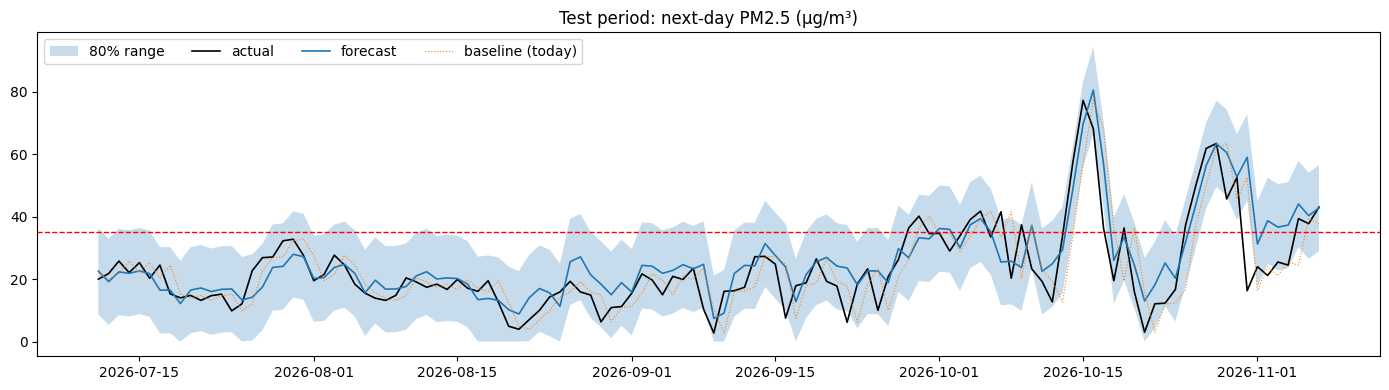

In [13]:
resid = oof_true - oof_ok
q_lo, q_hi = np.percentile(resid, [10, 90])
lo = (test_pred + q_lo).clip(lower=0)
hi = test_pred + q_hi
coverage = float(((y_test >= lo) & (y_test <= hi)).mean())
print(f"Typical range: forecast {q_lo:+.1f} to {q_hi:+.1f} µg/m³")
print(f"The 80% range contained the real value on {coverage:.0%} of test days (it should be close to 80%).")

fig, ax = plt.subplots(figsize=(14, 4))
ax.fill_between(test.index, lo, hi, alpha=0.25, label="80% range")
ax.plot(test.index, y_test, color="black", lw=1.2, label="actual")
ax.plot(test.index, test_pred, color="tab:blue", lw=1.2, label="forecast")
ax.plot(test.index, persist, color="tab:orange", lw=0.8, ls=":", label="baseline (today)")
ax.axhline(WARN_LEVEL, color="red", ls="--", lw=1)
ax.set_title("Test period: next-day PM2.5 (µg/m³)")
ax.legend(ncol=4)
plt.tight_layout()
plt.show()

## 10. What drives pollution here?

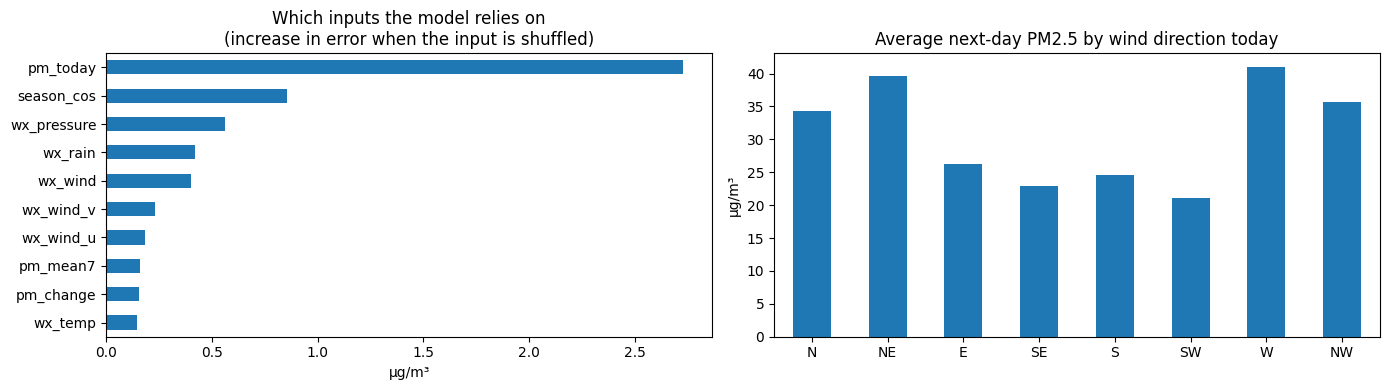

Days per wind direction: {'N': 73, 'NE': 112, 'E': 157, 'SE': 39, 'S': 13, 'SW': 33, 'W': 118, 'NW': 97}
Average next-day PM2.5 on the calmest quarter of days: 52.1 µg/m³, on the windiest quarter: 18.9 µg/m³


In [14]:
imp = permutation_importance(hgb, test[HONEST], y_test, n_repeats=10, scoring="neg_mean_absolute_error",
                             random_state=SEED)
imp_s = pd.Series(imp.importances_mean, index=HONEST).sort_values(ascending=False).head(10)
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
imp_s[::-1].plot.barh(ax=axes[0])
axes[0].set_title("Which inputs the model relies on\n(increase in error when the input is shuffled)")
axes[0].set_xlabel("µg/m³")

# wind direction (where the wind comes FROM), today's wind vs tomorrow's PM2.5
dirs = (np.degrees(np.arctan2(-model_df["wx_wind_u"], -model_df["wx_wind_v"])) % 360)
labels = ["N", "NE", "E", "SE", "S", "SW", "W", "NW"]
octant = pd.cut((dirs + 22.5) % 360, bins=np.arange(0, 361, 45), labels=labels, right=False)
by_dir = model_df.groupby(octant)["target"].agg(["mean", "count"])
by_dir["mean"].plot.bar(ax=axes[1], rot=0)
axes[1].set_title("Average next-day PM2.5 by wind direction today")
axes[1].set_ylabel("µg/m³")
plt.tight_layout()
plt.show()

print("Days per wind direction:", by_dir["count"].to_dict())
calm = model_df["wx_wind"] <= model_df["wx_wind"].quantile(0.25)
print(f"Average next-day PM2.5 on the calmest quarter of days: {model_df.loc[calm, 'target'].mean():.1f} µg/m³,"
      f" on the windiest quarter: {model_df.loc[model_df['wx_wind'] >= model_df['wx_wind'].quantile(0.75), 'target'].mean():.1f} µg/m³")

## 11. Key results
Printed automatically from the runs above, so the text always matches the numbers.

In [15]:
best_honest = "Gradient boosting (honest features)"
b = table.loc["Baseline: tomorrow = today"]
m_ = table.loc[best_honest]
o_ = table.loc["Gradient boosting + tomorrow's real weather (UPPER BOUND)"]
print("KEY RESULTS")
print("-----------")
print(f"1. Data: {SOURCE_NOTE}. {city_name}, {daily.index.min().date()} to {daily.index.max().date()}.")
print(f"2. Test period: {test.index.min().date()} to {test.index.max().date()} ({len(test)} days).")
print(f"3. Mean absolute error: baseline {b['MAE']:.2f} µg/m³, honest model {m_['MAE']:.2f} ({1 - m_['MAE'] / b['MAE']:+.0%} vs baseline).")
print(f"4. With tomorrow's REAL weather (not available to a real forecaster): {o_['MAE']:.2f} ({1 - o_['MAE'] / b['MAE']:+.0%}). This is an upper bound.")
print(f"5. Across {len(cv_table)} earlier 90-day periods, the model beats the baseline in {wins}.")
w_b, w_m = warn_pooled.iloc[0], warn_pooled.iloc[1]
print(f"6. Warnings, pooled over {len(cv_table)} earlier periods ({int(w_b['bad days'])} bad days): the baseline caught {int(w_b['warned (correct)'])} with {int(w_b['false alarms'])} false alarms; "
      f"the model caught {int(w_m['warned (correct)'])} with {int(w_m['false alarms'])} false alarms. "
      f"(The final test period had {int(warn_table.iloc[0]['bad days'])} bad days.)")
print(f"7. The 80% forecast range contained the truth on {coverage:.0%} of test days.")
print()
print("Our interpretation of these results is in the next section.")

KEY RESULTS
-----------
1. Data: OpenAQ station measurements: Porta Venezia (2.2 km from the city centre). Milan, 2024-11-14 to 2026-11-08.
2. Test period: 2026-07-11 to 2026-11-07 (120 days).
3. Mean absolute error: baseline 6.70 µg/m³, honest model 5.68 (+15% vs baseline).
4. With tomorrow's REAL weather (not available to a real forecaster): 4.85 (+28%). This is an upper bound.
5. Across 4 earlier 90-day periods, the model beats the baseline in 4.
6. Warnings, pooled over 4 earlier periods (135 bad days): the baseline caught 113 with 23 false alarms; the model caught 115 with 33 false alarms. (The final test period had 20 bad days.)
7. The 80% forecast range contained the truth on 92% of test days.

Our interpretation of these results is in the next section.


### Our interpretation
- **Is it worth using?** For the forecast number, yes. Average error falls from 6.70 to 5.68 µg/m³ (15% lower),
  and the model beats "tomorrow equals today" in all 4 earlier periods. [Add the bootstrap result.]
  As a yes/no warning, no: it caught 115 of 135 bad days against 113 for the simple rule, with 33 false
  alarms against 23. Bad days come in multi-day episodes, so "today is bad" already predicts tomorrow well.
- **Why a missed warning counts 3 times a false alarm:** [your reasoning: children and people with asthma or
  heart conditions outdoors on a bad day vs. a day spent indoors]. Even with that weighting, the simple rule
  scores slightly better (cost 89 vs 93), so we cannot claim the model improves the warning.
- **Main caveats:** one station and about two years of data; only 20 bad days in the final test period;
  the 80% range held on 92% of days (too cautious, probably because winter is in the training data);
  only today's weather is used, not a forecast; the live tab is not evaluated.

**Latest forecast add-on**

In [16]:
def openmeteo_weather_recent(lat, lon, days=21):
    # Recent daily weather from Open-Meteo's forecast API (the archive API lags a few days behind)
    d = get_json("https://api.open-meteo.com/v1/forecast",
                 {"latitude": lat, "longitude": lon, "hourly": ",".join(WX_VARS),
                  "past_days": days, "forecast_days": 1, "timezone": "auto"})
    h = pd.DataFrame(d["hourly"])
    h["time"] = pd.to_datetime(h["time"])
    rad = np.deg2rad(h["wind_direction_10m"])
    h["wind_u"] = -h["wind_speed_10m"] * np.sin(rad)
    h["wind_v"] = -h["wind_speed_10m"] * np.cos(rad)
    h["date"] = h["time"].dt.normalize()
    return h.groupby("date").agg(
        temp=("temperature_2m", "mean"), humidity=("relative_humidity_2m", "mean"),
        rain=("precipitation", "sum"), wind=("wind_speed_10m", "mean"),
        wind_u=("wind_u", "mean"), wind_v=("wind_v", "mean"), pressure=("surface_pressure", "mean"))

def make_live_row(pm, wx):
    # Same features as in training, built for the latest complete day only
    idx = pd.date_range(pm.index.max() - pd.Timedelta(days=13), pm.index.max(), freq="D")
    f = pd.DataFrame({"pm25": pm}).reindex(idx).join(wx)
    f["pm25"] = f["pm25"].interpolate(limit=2, limit_area="inside")
    f["pm_today"] = f["pm25"]
    f["pm_lag1"] = f["pm25"].shift(1)
    f["pm_lag2"] = f["pm25"].shift(2)
    f["pm_mean7"] = f["pm25"].rolling(7, min_periods=5).mean()
    f["pm_change"] = f["pm_today"] - f["pm_lag1"]
    doy = f.index.dayofyear
    f["season_sin"] = np.sin(2 * np.pi * doy / 365.25)
    f["season_cos"] = np.cos(2 * np.pi * doy / 365.25)
    f["tomorrow_weekend"] = ((f.index + pd.Timedelta(days=1)).dayofweek >= 5).astype(int)
    for c in WX:
        f["wx_" + c] = f[c]
    row = f.iloc[[-1]]
    missing = [c for c in HONEST if pd.isna(row[c].iloc[0])]
    if missing:
        raise RuntimeError(f"missing inputs for the latest day: {missing}")
    return row

def live_forecast(*_):
    try:
        if not OPENAQ_API_KEY:
            return ("**The live forecast needs an OpenAQ key** (stored as OPENAQ_API_KEY in Colab Secrets). "
                    "The replay tab works without it.")
        if "OpenAQ" not in SOURCE_NOTE:
            return "The live forecast only works when the model was trained on OpenAQ station data."
        station = SOURCE_NOTE.split(": ", 1)[1].rsplit(" (", 1)[0]
        sensors = openaq_find_sensors(lat, lon)
        mine = [s for s in sensors if s["station"] == station] or sensors
        if not mine:
            return "Could not find the OpenAQ sensor right now. Try again later."
        today = pd.Timestamp.today().normalize()
        pm = openaq_pm25_daily(mine[0]["sensor_id"], (today - pd.Timedelta(days=21)).date(), today.date())
        pm = pm[pm.index < today]                      # only complete days
        if len(pm) < 5:
            return "Not enough recent readings from the station right now. Try again later."
        wx_recent = openmeteo_weather_recent(lat, lon)
        row = make_live_row(pm, wx_recent)
        last_day = row.index[0]
        pred = float(hgb.predict(row[HONEST])[0])
        low, high = max(0.0, pred + q_lo), pred + q_hi
        label, advice = outlook(pred)
        target = (last_day + pd.Timedelta(days=1)).strftime("%Y-%m-%d")
        return (f"### Latest forecast for {target}: {label}\n\n"
                f"**Expected PM2.5:** {pred:.0f} µg/m³ (likely between {low:.0f} and {high:.0f})\n\n"
                f"**Advice:** {advice}\n\n---\n\n"
                f"**Based on the latest complete day, {last_day.strftime('%Y-%m-%d')}:** "
                f"{float(row['pm_today'].iloc[0]):.0f} µg/m³ at {station}.\n\n"
                f"_Add-on, **not evaluated**: it applies the same model to the newest readings. "
                f"Weather inputs come from Open-Meteo's forecast API, which can differ slightly from the "
                f"archive data used for training. A helper for planning, not an official health warning._")
    except Exception as e:
        return f"The live forecast is unavailable right now ({str(e)[:150]}). The replay tab still works."

## 12. Demo: replay past days
The first tab replays days from the test period (never used for training); the second tab is an unevaluated add-on that uses the latest readings.

In [17]:
import gradio as gr

test_dates = [x.strftime("%Y-%m-%d") for x in test.index]

def outlook(value):
    if value >= WARN_FORECAST:
        return ("🔴 Limit outdoor time",
                "Keep children's outdoor play and sport short, and consider moving activities indoors. "
                "People with asthma or heart conditions should be especially careful.")
    if value >= CAUTION_LEVEL:
        return ("🟠 Be careful",
                "Air quality may be poor for sensitive people. Watch for coughing or breathing trouble outdoors.")
    return ("🟢 Fine for most people", "No special precautions expected.")

def replay(date_str):
    ts = pd.Timestamp(date_str)
    row = test.loc[[ts]]
    pred = float(hgb.predict(row[HONEST])[0])
    low, high = max(0.0, pred + q_lo), pred + q_hi
    label, advice = outlook(pred)
    actual = float(row["target"].iloc[0])
    today = float(row["pm_today"].iloc[0])
    nxt = (ts + pd.Timedelta(days=1)).strftime("%Y-%m-%d")
    verdict = "the forecast and reality agree on the outlook" if outlook(actual)[0] == label else "the outlook was different from reality"
    return (f"### Forecast for {nxt}: {label}\n\n"
            f"**Expected PM2.5:** {pred:.0f} µg/m³ (likely between {low:.0f} and {high:.0f})\n\n"
            f"**Advice:** {advice}\n\n"
            f"---\n\n"
            f"**Reading on {date_str}:** {today:.0f} µg/m³  \n"
            f"**What actually happened on {nxt}:** {actual:.0f} µg/m³ ({outlook(actual)[0]}), so {verdict}.\n\n"
            f"_Replay of a past day from the test period, not a live forecast. {SOURCE_NOTE}. "
            f"A helper for planning, not an official health warning._")

demo = gr.Interface(
    fn=replay,
    inputs=gr.Dropdown(choices=test_dates, value=test_dates[-1], label="Pick a day (the forecast is for the day after)"),
    outputs=gr.Markdown(),
    title=f"Next-day air quality forecast: {city_name}",
    description="Replays past days the model never saw during training, next to what actually happened.",
    flagging_mode="never",
)

In [18]:
live_demo = gr.Interface(
    fn=live_forecast, inputs=None, outputs=gr.Markdown(),
    title="Latest forecast (add-on, not evaluated)",
    description="Press Submit to forecast from the newest station reading. Needs an OpenAQ key.",
    flagging_mode="never")

app = gr.TabbedInterface([demo, live_demo], ["Replay past days", "Latest forecast"])
app.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://47bb592de4910b3ef9.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


# Where the  outlook differs from reality

In [19]:
pred = pd.Series(hgb.predict(test[HONEST]), index=test.index)
res = pd.DataFrame({"reading": test["pm_today"].round(), "forecast": pred.round(), "actual": test["target"].round(),
                    "forecast outlook": [outlook(v)[0] for v in pred], "actual outlook": [outlook(v)[0] for v in test["target"]]})
res["actual inside range"] = (test["target"] >= (pred + q_lo).clip(lower=0)) & (test["target"] <= pred + q_hi)
res.index = res.index.strftime("%Y-%m-%d")
diff = res[res["forecast outlook"] != res["actual outlook"]]
print(len(diff), "of", len(res), "test days have a different outlook")
print(diff.head(15).to_string())

39 of 120 test days have a different outlook
            reading  forecast  actual        forecast outlook          actual outlook  actual inside range
date                                                                                                      
2026-07-20     14.0      16.0    15.0            🟠 Be careful  🟢 Fine for most people                 True
2026-07-21     15.0      17.0    13.0            🟠 Be careful  🟢 Fine for most people                 True
2026-07-22     13.0      16.0    15.0            🟠 Be careful  🟢 Fine for most people                 True
2026-07-24     15.0      17.0    10.0            🟠 Be careful  🟢 Fine for most people                 True
2026-07-26     12.0      14.0    23.0  🟢 Fine for most people            🟠 Be careful                 True
2026-07-29     27.0      24.0    32.0            🟠 Be careful    🔴 Limit outdoor time                 True
2026-07-30     32.0      28.0    33.0            🟠 Be careful    🔴 Limit outdoor time              

## 13. Limitations
- **Data source.** If the run used Open-Meteo estimates, the model learns to predict *another model's output*, not measured air. This is a weaker claim, and the key results section states which source was used. One station also may not represent the whole city.
- **Weather.** The honest model uses today's weather only. A real system would add tomorrow's weather *forecast*, which has its own errors; the upper-bound result shows what is at stake, not what a real system would achieve.
- **Short test period.** A few months, usually one season. The expanding-window check helps, but bad days are few, so warning counts are small and uncertain.
- **Choices that are judgements.** The cost ratio for missed warnings, the 35 and 15 µg/m³ levels and the 80% range are choices, not facts. The levels come from the US EPA standard and the WHO guideline and are used here as simple planning bands, not official health advice.
- **Not an official warning.** Do not rely on this for health decisions; follow the local air-quality authority.
- **Other pollutants, other places.** Only PM2.5 and one city are covered.

## 14. References
- OpenAQ, open air-quality measurements (api.openaq.org).
- Open-Meteo, historical weather and air-quality APIs (open-meteo.com), licensed CC BY 4.0. Air-quality values are model estimates.
- US EPA 24-hour PM2.5 standard (35 µg/m³) and the WHO 2021 air-quality guideline for 24-hour PM2.5 (15 µg/m³).
- Tools: pandas, NumPy, scikit-learn, Matplotlib, Gradio.